## Load tickers

In [7]:
import findspark
# initialize findspark with spark directory
findspark.init()
# import pyspark
import pyspark
# create spark context
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

ValueError: Cannot run multiple SparkContexts at once; existing SparkContext(app=pyspark-shell, master=local[*]) created by __init__ at C:\Users\renzo\AppData\Local\Temp\ipykernel_45960\4103633412.py:7 

In [ ]:
spark

In [8]:
import pandas as pd

In [9]:
tickers = pd.read_csv("../../Data/tickers.csv")

In [10]:
tickers

,tickers,Company Name
0,ARG.TO,Amerigo Resources Ltd
1,AYA.TO,Aya Gold & Silver Inc
2,CG.TO,Centerra Gold Inc
3,CGC.V,Canadian Gold Corp
4,CKG.V,Chesapeake Gold Corp
5,DMX.V,District Metals Corp
6,DV.V,Dolly Varden Silver Corp
7,EDG.V,Endurance Gold Corp
8,ELO.TO,Eloro Resources Ltd
9,EQX,Equinox Gold Corp


## Criteria

Maturity level are identified based on info gathered from each companies website

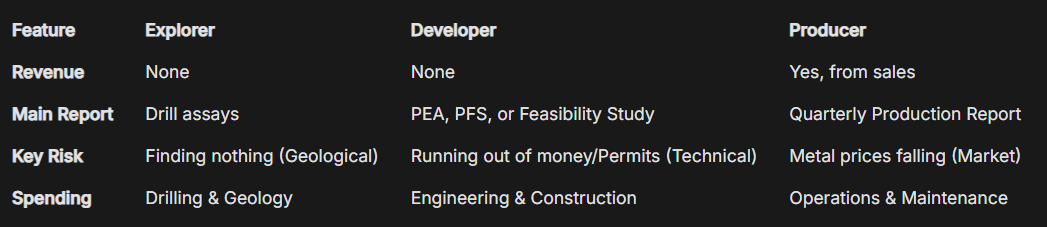

In [11]:
maturity_level = list()

In [ ]:
maturity_level.extend([{"ARG.TO": "Producer"}, {"AYA.TO": "Producer"},
        {"CG.TO": "Producer"}, {"CGC.V": "Developer"}, {"CKG.V": "Developer"},
        {"DMX.V": "Explorer"}, {"DV.V": "Explorer"}, {"EDG.V":"Explorer"},
        {"ELO.TO": "Explorer"}, {"EQX":"Producer"}, {"ESK.V":"Explorer"},
        {"FAS.V":""}, {"FDY.TO":""}, {"FINX.V":"Explorer"},
        {"FNM.V":"Explorer"}, {"FOM.TO":"Developer"}, {"FURY.TO":"Explorer"},
        {"FVL.TO":"Developer"}, {"FWZ.V":"Developer"}
    ])

# Merge with basetable

In [12]:
maturity_level = pd.read_csv("../../Data/Categorical/maturity_level.csv")

In [13]:
maturity_level.head()

,ticker,maturity
0,ARG.TO,Producer
1,AYA.TO,Producer
2,CG.TO,Producer
3,CGC.V,Explorer
4,CKG.V,Explorer


In [4]:
basetable = spark.read.parquet("../../Cleaned_data/biweekly_basetable.parquet")

In [5]:
basetable.show()

+------+--------------+---------------+--------------------+--------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+
|ticker|biweekly_index|biweekly_period|            longname|industry|benchmark|period_start|period_end|period_open|period_close|period_high|period_low|         avg_close|       period_return|benchmark_period_return|                beta|    price_volatility|   return_volatility|  avg_intraday_range|  max_intraday_range|total_volume|  avg_daily_volume|max_daily_volume| volume_volatility|avg_volume_up_days|avg_volume_down_days|ga

In [14]:
spark_maturity_level = spark.createDataFrame(maturity_level)

In [16]:
# 3) Left join onto basetable and maturity
joined = (
    basetable
    .join(spark_maturity_level, on=["ticker"], how="left")
)
joined.show()

+------+--------------+---------------+--------------------+--------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+
|ticker|biweekly_index|biweekly_period|            longname|industry|benchmark|period_start|period_end|period_open|period_close|period_high|period_low|         avg_close|       period_return|benchmark_period_return|                beta|    price_volatility|   return_volatility|  avg_intraday_range|  max_intraday_range|total_volume|  avg_daily_volume|max_daily_volume| volume_volatility|avg_volume_up_days|avg_volume_dow

In [17]:
joined.write.mode("overwrite").parquet("../Cleaned_data/biweekly_basetable.parquet")